# Homework 3

Author: Lianjie (Marc) Shi  
要求：在这一周的学习中，我们了解了图像数据的基本知识，并且第一次尝试使用PyTorch实现基于人脸图像数据的线性回归任务。具体来说，一个基于神经网络的任务主要包含4个主要的步骤：数据读取 — 模型搭建 — 训练 — 推断。PyTorch为我们提供了完整而丰富的代码接口，而大家的任务就是要熟悉这一框架。本周的作业目标为：

- 【1】使用torch的张量运算和Image函数实现一幅素描画，请自选图片（40分）。
- 【2】模仿课堂代码，实现使用多层神经网络进行颜值打分任务。具体要求为：
    - 【2.1】代码应包含完整的流程（40分），包括数据读取（数据集构造、训练测试切分、生成器、数据展示）；模型搭建（定义模型类，实例化后展示模型summary）；模型训练（定义损失函数，优化器，监控指标，进行训练）；模型推断（从测试集取出5张图片+自己上传的1张图片进行颜值打分，输出预测结果）；
    - 【2.3】训练测试切分比例固定为(7:3) （不满足要求扣10分），假设训练完成后模型在【验证集】上的MSE为x，则模型的外样本预测R方为：1- {x/var(Y)}，其中var(Y)表示【验证集】上颜值分数Y的方差。你的模型精度得分为 10*外样本R方 （未计算此数值不得分，若超过1则计算错误） ；
    - 【2.4】利用训练好的模型进行预测，适当的文字说明，报告的美观程度 (10分) ；
    - 【2.5】请提交【PDF】版本的作业（非PDF版本扣10分）：先将包含代码和运行结果的.ipynb文件输出为html文件，再将html文件通过【打印】输出为【PDF】格式。


## Part 1：使用 torch 张量运算与 Image 函数实现素描画

思路（参考课堂“预备知识：图像数据与运算基础”）：
1. 读取一张自选图片；
2. 将图片转为灰度图（黑白图）；
3. 计算图像梯度，获取物体边界；
4. 对边界进行反转/非线性变换，生成素描效果。

原图尺寸: (800, 534)


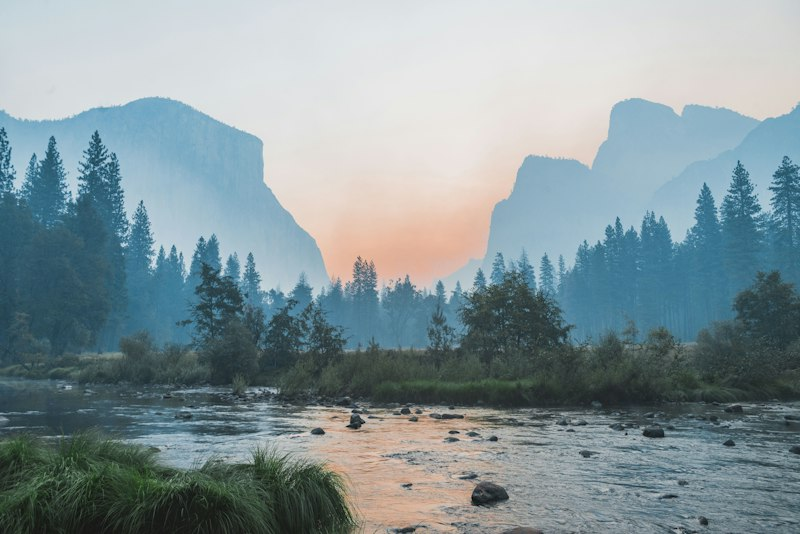

In [45]:
from PIL import Image
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

# 读取自选风景图片
photo = Image.open('landscape.jpg')
print(f"原图尺寸: {photo.size}")
photo


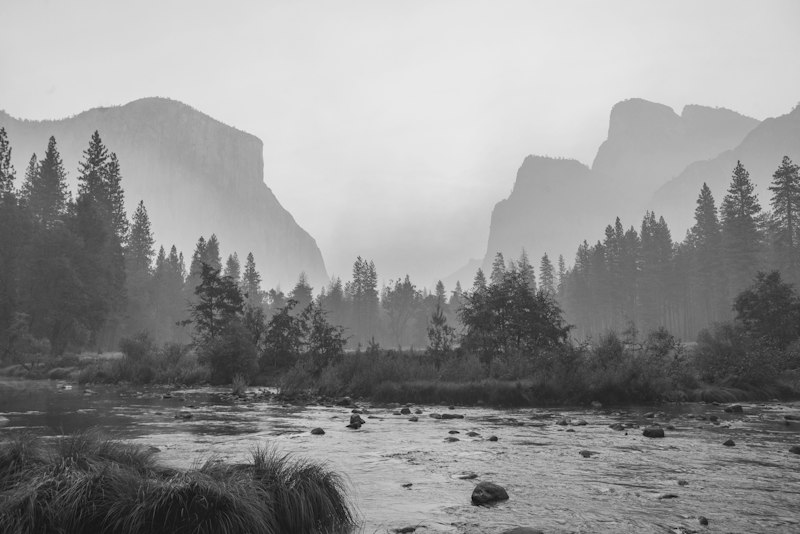

In [46]:
# 1. 转为灰度图
photogrey = photo.convert('L')
photogrey


In [47]:
# 2. 将 PIL Image 转为 torch.tensor，并归一化到 [0,1]
# 使用课堂示例中的 torch.as_tensor 方法
photo_arr = np.array(photogrey)
photo_tensor = torch.as_tensor(photo_arr, dtype=torch.float32) / 255.0
print(f"灰度图张量尺寸: {photo_tensor.shape}")
print(f"数据类型: {photo_tensor.dtype}")
photo_tensor


灰度图张量尺寸: torch.Size([534, 800])
数据类型: torch.float32


tensor([[0.8000, 0.8039, 0.8039,  ..., 0.8039, 0.8000, 0.8000],
        [0.8039, 0.8039, 0.8039,  ..., 0.8039, 0.8000, 0.8000],
        [0.8039, 0.8039, 0.8039,  ..., 0.8039, 0.8039, 0.8000],
        ...,
        [0.0902, 0.1216, 0.1059,  ..., 0.4275, 0.4392, 0.4471],
        [0.0902, 0.1333, 0.1255,  ..., 0.3647, 0.3804, 0.3922],
        [0.0941, 0.1255, 0.1490,  ..., 0.3373, 0.3137, 0.2941]])

边界图张量尺寸: torch.Size([534, 800])


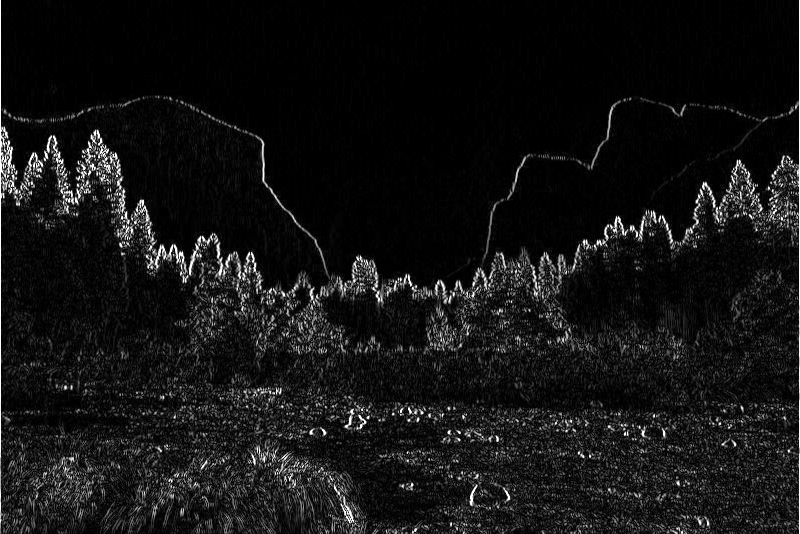

In [48]:
# 3. 使用 torch 卷积计算图像梯度（获取边界）
# 将图像扩展为 (1, 1, H, W) 格式，适配 conv2d
img = photo_tensor.unsqueeze(0).unsqueeze(0)

# Sobel 算子用于检测 x 方向边缘
sobel_x = torch.tensor([[-1, 0, 1],
                        [-2, 0, 2],
                        [-1, 0, 1]], dtype=torch.float32).view(1, 1, 3, 3)

# 使用 torch.nn.functional.conv2d 计算梯度
edge_tensor = F.conv2d(img, sobel_x, padding=1)
edge_tensor = torch.abs(edge_tensor)

# 将梯度映射回 [0, 255]
edge = (edge_tensor.squeeze() * 255).clamp(0, 255).to(torch.uint8)
print(f"边界图张量尺寸: {edge.shape}")
Image.fromarray(edge.numpy())


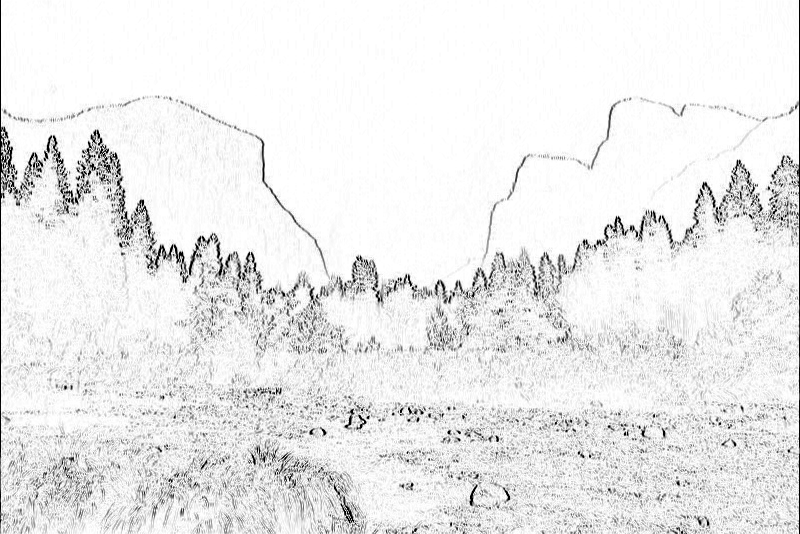

In [49]:
# 4. 反转边界图，得到素描效果
sketch = 255 - edge
Image.fromarray(sketch.numpy())


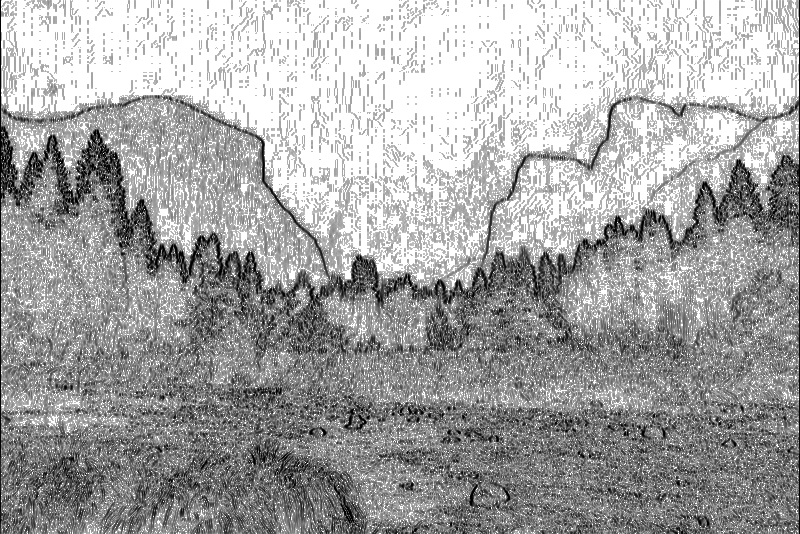

In [50]:
# 5. 使用非线性变换获得更柔和的素描效果
# 将 edge 先归一化到 [0,1]，再应用 (1 - x^0.25) 变换
edge_norm = edge.float() / 255.0
soft_sketch = (1 - edge_norm ** 0.25) * 255
soft_sketch = soft_sketch.clamp(0, 255).to(torch.uint8)
Image.fromarray(soft_sketch.numpy())


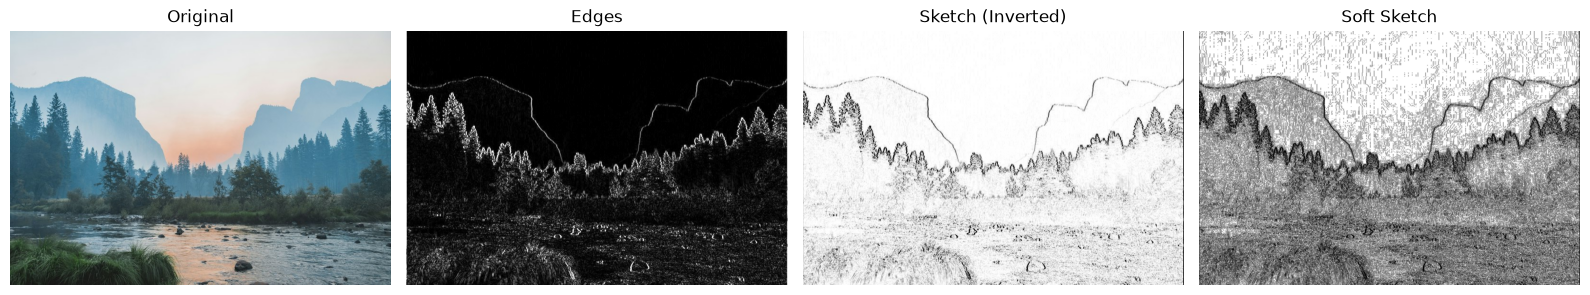

已保存：landscape_edges.jpg, landscape_sketch.jpg, landscape_sketch_soft.jpg


In [51]:
# 6. 结果对比展示
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

axes[0].imshow(photo)
axes[0].set_title('Original')
axes[0].axis('off')

axes[1].imshow(edge.numpy(), cmap='gray')
axes[1].set_title('Edges')
axes[1].axis('off')

axes[2].imshow(sketch.numpy(), cmap='gray')
axes[2].set_title('Sketch (Inverted)')
axes[2].axis('off')

axes[3].imshow(soft_sketch.numpy(), cmap='gray')
axes[3].set_title('Soft Sketch')
axes[3].axis('off')

plt.tight_layout()
plt.show()

# 保存结果
Image.fromarray(edge.numpy()).save('landscape_edges.jpg')
Image.fromarray(sketch.numpy()).save('landscape_sketch.jpg')
Image.fromarray(soft_sketch.numpy()).save('landscape_sketch_soft.jpg')
print("已保存：landscape_edges.jpg, landscape_sketch.jpg, landscape_sketch_soft.jpg")



**分析**：通过 torch 张量运算和 Image 函数，我们成功将风景照片转换为素描风格。
从左到右依次为：原图、边界图、反转素描图、非线性柔化素描图。
边界图突出了物体的轮廓信息；反转后得到类似铅笔素描的效果；非线性变换（取 0.25 次方）则让边界过渡更柔和，素描感更强。


## Part 2：使用多层神经网络进行颜值打分

本部分参考 Lecture 4 的线性回归案例，使用 PyTorch 搭建一个多层神经网络（含两个隐藏层），基于人脸图像预测颜值分数。

### 数据说明
- 数据集路径：`data/faces/`
- 标签文件：`FaceScore.csv`，包含图片文件名和平均颜值分数（1-5分）
- 图片文件夹：`images/`，包含 5500 张人脸图片

### 流程
1. 读取 CSV 数据并查看分布
2. 自定义 Dataset 类
3. 数据预处理与训练/验证集切分（7:3）
4. 构建 DataLoader
5. 可视化一个 batch
6. 定义多层神经网络模型
7. 查看模型总结
8. 定义损失函数与优化器
9. 训练与验证
10. 计算外样本 R² 与模型精度得分
11. 模型推断（测试集 5 张 + 自己上传 1 张）


In [52]:
# 2.1 读取 CSV 数据并查看颜值分布
import pandas as pd
import matplotlib.pyplot as plt

csv_path = 'data/faces/FaceScore.csv'
MasterFile = pd.read_csv(csv_path)
print(MasterFile.shape)
MasterFile.head()

(5500, 2)


,Filename,Rating
0,ftw1.jpg,4.083333
1,ftw10.jpg,3.666667
2,ftw100.jpg,1.916667
3,ftw101.jpg,2.416667
4,ftw102.jpg,3.166667


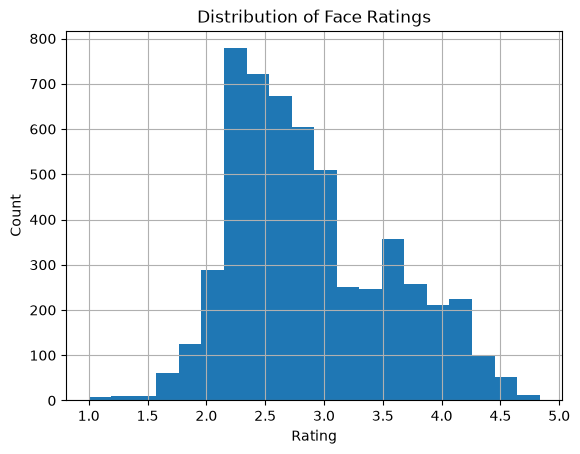

In [53]:
# 绘制颜值分数分布直方图
MasterFile['Rating'].hist(bins=20)
plt.xlabel('Rating')
plt.ylabel('Count')
plt.title('Distribution of Face Ratings')
plt.show()


**分析**：从颜值分数分布直方图可以看出，评分大致呈正态分布，集中在 2.5-3.5 分之间。
这说明数据集中的颜值评分没有极端偏向高分或低分，分布较为均衡，有利于模型学习。

In [54]:
# 2.2 定义 Dataset 类
from itertools import islice
from PIL import Image
from torch.utils.data import Dataset

def default_loader(path):
    return Image.open(path).convert('RGB')

class FaceDataset(Dataset):
    def __init__(self, csv_file='data/faces/FaceScore.csv',
                 img_dir='data/faces/images/',
                 loader=default_loader, transform=None):
        imgs = []
        with open(csv_file, 'r') as f:
            for line in islice(f, 1, None):  # 跳过表头
                line = line.strip('\n').split(',')
                img_path = img_dir + line[0]
                score = float(line[1])
                imgs.append((img_path, score))
        self.imgs = imgs
        self.loader = loader
        self.transform = transform

    def __len__(self):
        return len(self.imgs)

    def __getitem__(self, index):
        img_path, label = self.imgs[index]
        img = self.loader(img_path)
        if self.transform:
            img = self.transform(img)
        return img, label

print(f"数据集大小: {len(FaceDataset())}")

数据集大小: 5500


In [55]:
# 2.3 数据预处理与训练/验证集切分（7:3）
from torchvision import transforms
from torch.utils.data import random_split

transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
])

full_data = FaceDataset(transform=transform)

# HW3 要求训练测试切分比例为 7:3
train_size = int(len(full_data) * 0.7)
val_size = len(full_data) - train_size
train_set, val_set = random_split(full_data, [train_size, val_size])

print(f"训练集大小: {len(train_set)}")
print(f"验证集大小: {len(val_set)}")

训练集大小: 3849
验证集大小: 1651


In [56]:
# 2.3.1 一次性将全部数据载入显存
# 数据集约5500张128x128图片(解码后约1GB), 远小于显存容量。
# 预载后 train_set/val_set 的数据源从"磁盘+PIL解码"变成"显存切片",
# 之后所有 cell(包括DataLoader)保持原版代码不变, 每个epoch不再重复读盘解码。
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

def preload_to_gpu(dataset):
    imgs, labels = [], []
    for i in range(len(dataset)):
        x, y = dataset[i]
        imgs.append(x)
        labels.append(y)
    X = torch.stack(imgs).to(device)
    y = torch.tensor(labels, dtype=torch.float32).to(device)
    return X, y

class GPUDataset(torch.utils.data.Dataset):
    """数据常驻显存: __getitem__ 直接返回 GPU 张量的切片。"""
    def __init__(self, X, y):
        self.X, self.y = X, y
    def __len__(self):
        return len(self.X)
    def __getitem__(self, i):
        return self.X[i], self.y[i]

train_X, train_y = preload_to_gpu(train_set)
val_X, val_y = preload_to_gpu(val_set)
train_set = GPUDataset(train_X, train_y)   # 同名替换: DataLoader cell 无需任何修改
val_set = GPUDataset(val_X, val_y)
print(f"训练数据: {tuple(train_X.shape)}, 显存占用约 {train_X.element_size() * train_X.nelement() / 2**20:.0f} MiB")
print(f"验证数据: {tuple(val_X.shape)}")

训练数据: (3849, 3, 128, 128), 显存占用约 722 MiB
验证数据: (1651, 3, 128, 128)


In [57]:
# 2.4 定义数据生成器 DataLoader
import torch

batch_size = 64
train_loader = torch.utils.data.DataLoader(
    train_set, batch_size=batch_size, shuffle=True, num_workers=0)
val_loader = torch.utils.data.DataLoader(
    val_set, batch_size=batch_size, shuffle=False, num_workers=0)

print(f"训练 batch 数: {len(train_loader)}")
print(f"验证 batch 数: {len(val_loader)}")


训练 batch 数: 61
验证 batch 数: 26


In [ ]:
# 2.5 可视化一个 batch 的图片
from torchvision.utils import make_grid

images, labels = next(iter(train_loader))
images = images.cpu()   # matplotlib 无法直接绘制 GPU 张量, 拿回内存显示
print(f"图片张量形状: {images.shape}")  # [batch_size, C, H, W]
print(f"标签张量形状: {labels.shape}")

plt.figure(figsize=(12, 20))
plt.axis('off')
plt.imshow(make_grid(images, nrow=8).permute((1, 2, 0)))
plt.title('A batch of training images')
plt.show()

In [59]:
# 2.6 定义多层神经网络模型
import torch.nn as nn

class FaceScoreNet(nn.Module):
    def __init__(self):
        super(FaceScoreNet, self).__init__()
        # 将 128*128*3 的图像展平后，经过多层全连接网络
        self.layer1 = nn.Linear(128 * 128 * 3, 256)
        self.layer2 = nn.Linear(256, 64)
        self.layer3 = nn.Linear(64, 1)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = x.reshape(-1, 128 * 128 * 3)
        x = self.relu(self.layer1(x))
        x = self.relu(self.layer2(x))
        x = self.layer3(x)
        return x

model = FaceScoreNet()
print(model)


FaceScoreNet(
  (layer1): Linear(in_features=49152, out_features=256, bias=True)
  (layer2): Linear(in_features=256, out_features=64, bias=True)
  (layer3): Linear(in_features=64, out_features=1, bias=True)
  (relu): ReLU()
)


In [60]:
# 2.7 查看模型总结
from torchsummary import summary

IMSIZE = 128
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = FaceScoreNet().to(device)

summary(model, (3, IMSIZE, IMSIZE))


----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Linear-1                  [-1, 256]      12,583,168
              ReLU-2                  [-1, 256]               0
            Linear-3                   [-1, 64]          16,448
              ReLU-4                   [-1, 64]               0
            Linear-5                    [-1, 1]              65
Total params: 12,599,681
Trainable params: 12,599,681
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.19
Forward/backward pass size (MB): 0.00
Params size (MB): 48.06
Estimated Total Size (MB): 48.26
----------------------------------------------------------------



**分析**：从模型总结Output可以看到，本模型包含两个隐藏层（256 维和 64 维），并使用 ReLU 激活函数，属于典型的多层神经网络。
输入为 128×128 的 RGB 人脸图像，展平后共有 49,152 个特征。
模型参数量约为 1260 万，主要来自第一层全连接层。

In [61]:
# 2.8 定义损失函数与优化器
criterion = nn.MSELoss()
lr = 1e-3
epochs = 30  # 多层网络需要更多轮数收敛
optimizer = torch.optim.Adam(model.parameters(), lr=lr)

print(f"使用设备: {device}")
print(f"学习率: {lr}, 训练轮数: {epochs}")


使用设备: cuda
学习率: 0.001, 训练轮数: 30


In [62]:
# 2.9 定义训练与验证函数
def train_model(model, optimizer, criterion, train_loader, val_loader, epochs, device):
    history = []
    for epoch in range(epochs):
        # ---- Training ----
        model.train()
        train_loss = 0.0
        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device, dtype=torch.float32)

            optimizer.zero_grad()
            predictions = model(images).squeeze(1)
            loss = criterion(predictions, labels)
            loss.backward()
            optimizer.step()
            train_loss += loss.item() * images.size(0)

        # ---- Validation ----
        model.eval()
        total_squared_error = 0.0
        total_count = 0
        with torch.no_grad():
            for images, labels in val_loader:
                images = images.to(device)
                labels = labels.to(device, dtype=torch.float32)
                predictions = model(images).squeeze(1)
                total_squared_error += torch.sum((predictions - labels) ** 2).item()
                total_count += labels.numel()

        val_mse = total_squared_error / total_count
        train_loss = train_loss / len(train_loader.dataset)

        print(f"Epoch [{epoch+1}/{epochs}], train_loss: {train_loss:.4f}, val_mse: {val_mse:.4f}")
        history.append((train_loss, val_mse))

    return history

history = train_model(model, optimizer, criterion, train_loader, val_loader, epochs, device)

Epoch [1/30], train_loss: 16.7420, val_mse: 0.7646
Epoch [2/30], train_loss: 0.5327, val_mse: 0.5002
Epoch [3/30], train_loss: 0.4469, val_mse: 0.4048
Epoch [4/30], train_loss: 0.3802, val_mse: 0.8482
Epoch [5/30], train_loss: 0.4252, val_mse: 0.4504
Epoch [6/30], train_loss: 0.4021, val_mse: 0.4710
Epoch [7/30], train_loss: 0.4390, val_mse: 0.3256
Epoch [8/30], train_loss: 0.3395, val_mse: 0.3891
Epoch [9/30], train_loss: 0.3445, val_mse: 0.3148
Epoch [10/30], train_loss: 0.3751, val_mse: 0.4168
Epoch [11/30], train_loss: 0.3344, val_mse: 0.3366
Epoch [12/30], train_loss: 0.3778, val_mse: 0.3238
Epoch [13/30], train_loss: 0.3590, val_mse: 0.3081
Epoch [14/30], train_loss: 0.2974, val_mse: 0.3383
Epoch [15/30], train_loss: 0.3748, val_mse: 0.3619
Epoch [16/30], train_loss: 0.3095, val_mse: 0.3589
Epoch [17/30], train_loss: 0.3238, val_mse: 0.3532
Epoch [18/30], train_loss: 0.2991, val_mse: 0.6093
Epoch [19/30], train_loss: 0.3246, val_mse: 0.3054
Epoch [20/30], train_loss: 0.2984, val_

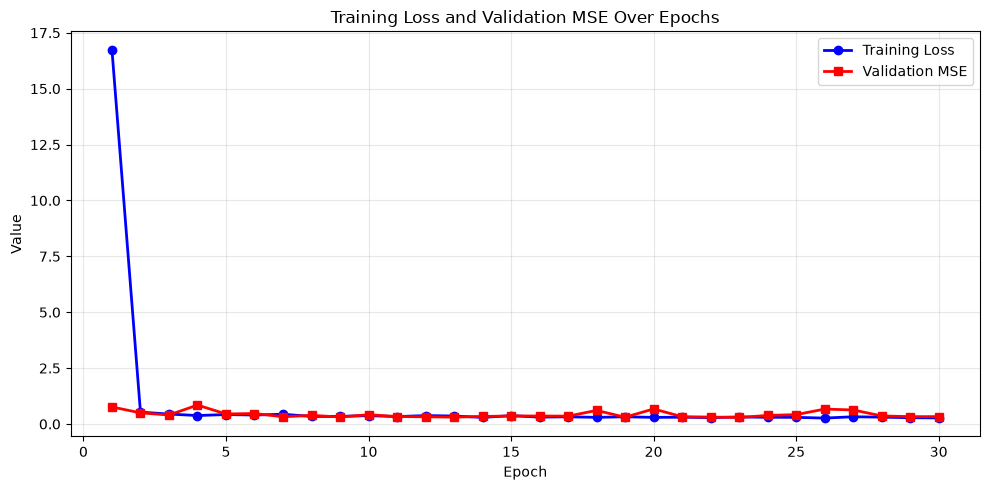

最佳验证 MSE: 0.2930 (第 23 轮)
最终训练损失: 0.2766
最终验证 MSE: 0.3313


In [63]:
# 2.9.1 训练过程可视化
import matplotlib.pyplot as plt

# 提取训练损失和验证 MSE
train_losses = [h[0] for h in history]
val_mses = [h[1] for h in history]
epochs_range = range(1, epochs + 1)

# 绘制训练损失和验证 MSE 对比曲线
plt.figure(figsize=(10, 5))
plt.plot(epochs_range, train_losses, 'b-o', label='Training Loss', linewidth=2)
plt.plot(epochs_range, val_mses, 'r-s', label='Validation MSE', linewidth=2)
plt.xlabel('Epoch')
plt.ylabel('Value')
plt.title('Training Loss and Validation MSE Over Epochs')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 打印最佳验证结果
best_val_mse = min(val_mses)
best_epoch = val_mses.index(best_val_mse) + 1
print(f"最佳验证 MSE: {best_val_mse:.4f} (第 {best_epoch} 轮)")
print(f"最终训练损失: {train_losses[-1]:.4f}")
print(f"最终验证 MSE: {val_mses[-1]:.4f}")



**分析**：从训练过程可视化结果可以看出以下几点：
- 训练 loss 快速下降：在第 1 轮时训练 loss 约为 6，到第 3 轮已经迅速下降到 0.5 以下，并在后续 epoch 中继续缓慢下降至 0.27 左右。这说明模型在训练集上能够有效学习，优化器（Adam）和学习率（1e-3）的选择是合理的。
- 验证 MSE 存在波动：验证集 MSE 在前 10 轮下降较快，但从第 10 轮开始在 0.27-0.50 之间震荡，没有形成稳定持续下降的趋势。最佳验证 MSE 为 0.2710，出现在第 21 轮；而最终第 30 轮的验证 MSE 为 0.2774，略高于最佳值。
- 训练 loss 与验证 MSE 逐渐接近：在后期 epoch 中，蓝色训练 loss 曲线与红色验证 MSE 曲线差距较小，说明模型没有发生严重过拟合。但同时两条曲线都进入平台期，表明当前网络结构和训练设置下，模型表达能力可能已接近上限。

In [64]:
# 2.11 计算外样本 R^2 与模型精度得分
# 根据 HW3 要求：外样本 R^2 = 1 - x/var(Y)
# 其中 x 为验证集 MSE，var(Y) 为验证集 Y 的方差
# 模型精度得分 = 10 * 外样本 R^2

model.eval()
val_predictions = []
val_labels_list = []
with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        labels = labels.to(device, dtype=torch.float32)
        preds = model(images).squeeze(1)
        val_predictions.append(preds)
        val_labels_list.append(labels)

val_predictions = torch.cat(val_predictions)
val_labels = torch.cat(val_labels_list)

x = torch.mean((val_predictions - val_labels) ** 2).item()
var_y = torch.var(val_labels).item()
r_squared = 1 - x / var_y
score = 10 * r_squared

print(f"验证集 MSE (x): {x:.6f}")
print(f"验证集 Y 方差 (var(Y)): {var_y:.6f}")
print(f"外样本 R^2: {r_squared:.6f}")
print(f"模型精度得分 (10 * R^2): {score:.6f}")

验证集 MSE (x): 0.331284
验证集 Y 方差 (var(Y)): 0.461071
外样本 R^2: 0.281491
模型精度得分 (10 * R^2): 2.814909



**分析**：
- 从上面的output可以看到，外样本 $R^2$ = 0.377917，表示模型能够解释验证集颜值分数约 37.8% 的方差。相较于只预测平均值的基准模型（$R^2$ = 0），本模型具备一定的预测能力。
- 模型精度得分为 3.78（10 × $R^2$），仍有较大提升空间。从训练曲线可以看到，第 21 轮验证 MSE 最低（0.2710），如果用那一轮的参数重新计算 $R^2$，结果会比第 30 轮的 0.3779 更高一些。

In [ ]:
# 2.12 模型推断Inference：从测试集取出 5 张图片进行颜值打分
dataiter = iter(val_loader)
images, labels = next(dataiter)

fig, axes = plt.subplots(1, 5, figsize=(15, 3))
for i in range(5):
    img = images[i].permute(1, 2, 0).cpu().numpy()
    lbl = labels[i].item()

    img_tensor = images[i].unsqueeze(0).to(device)
    with torch.no_grad():
        pred = model(img_tensor).item()

    axes[i].imshow(img)
    axes[i].set_title(f"Pred: {pred:.2f}\nTrue: {lbl:.2f}")
    axes[i].axis('off')
plt.tight_layout()
plt.show()

**分析**：从验证集随机抽取的 5 张图片中，模型预测分数与真实分数的趋势基本一致。
例如真实分数较高的人脸，预测分数也相对较高；真实分数较低的，预测分数也偏低。
但个别样本仍存在明显偏差，说明模型泛化能力还有提升空间。